# Tarea 1 · Parte 1 – Recolección de noticias de El Comercio

**Pregunta guía:** ¿podemos convertir titulares peruanos en un clasificador de noticias?

| Dato | Valor |
| :--- | :--- |
| Fecha de descarga | 18 de octubre de 2026 |
| Opción elegida | **B – El Comercio** (`elcomercio.pe`) |
| Fuente | Sitemaps oficiales de noticias por sección (listados en `robots.txt`) + página de cada noticia para la bajada |
| URLs base | `https://elcomercio.pe/sitemap/news/politica/?outputType=xml`<br>`https://elcomercio.pe/sitemap/news/economia/?outputType=xml`<br>`https://elcomercio.pe/sitemap/news/deporte-total/?outputType=xml`<br>`https://elcomercio.pe/sitemap/news/tecnologia/?outputType=xml` |
| Categorías | `politica`, `economia`, `deportes`, `ciencia_tecnologia` |

**¿Por qué El Comercio y no La República?** Lo probamos primero con La República. Su RSS
oficial solo devuelve entre 7 y 21 noticias por sección, la paginación de sus secciones
siempre repite las mismas 16 noticias y su API interna responde `403` a cualquier cliente
que no sea un navegador. No forzamos ese bloqueo. Los sitemaps de El Comercio, en
cambio, están publicados en su `robots.txt` y traen las últimas 100 noticias de cada
sección, con titular y fecha.

In [1]:
import time
import urllib.robotparser
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.io as pio
import requests
from bs4 import BeautifulSoup

# png además del gráfico interactivo: GitHub no muestra los gráficos de Plotly sin imagen
pio.renderers.default = "plotly_mimetype+png"
pd.set_option("display.max_colwidth", 90)

## 1. Configuración y buenas prácticas de scraping

Un `User-Agent` que dice quiénes somos, una pausa de 1.5 segundos entre solicitudes y
como máximo un reintento.

In [2]:
USER_AGENT = "Mozilla/5.0 (compatible; TareaAcademicaPUCP/1.0; clasificador de titulares)"
PAUSA_SEGUNDOS = 1.5
FECHA_DESCARGA = "2026-10-18"
MEDIO = "El Comercio"

secciones_sitemap = {
    "politica": "https://elcomercio.pe/sitemap/news/politica/?outputType=xml",
    "economia": "https://elcomercio.pe/sitemap/news/economia/?outputType=xml",
    "deporte-total": "https://elcomercio.pe/sitemap/news/deporte-total/?outputType=xml",
    "tecnologia": "https://elcomercio.pe/sitemap/news/tecnologia/?outputType=xml",
}

carpeta_raw = Path("datos/raw")
carpeta_raw.mkdir(parents=True, exist_ok=True)

Antes de descargar nada, le preguntamos a `robots.txt` si podemos leer cada URL.

In [3]:
robots = urllib.robotparser.RobotFileParser("https://elcomercio.pe/robots.txt")
robots.read()

for seccion, url in secciones_sitemap.items():
    print(f"{seccion:15} permitido: {robots.can_fetch(USER_AGENT, url)}")

ejemplo_noticia = "https://elcomercio.pe/politica/congreso/una-noticia-noticia/"
print(f"{'noticias':15} permitido: {robots.can_fetch(USER_AGENT, ejemplo_noticia)}")

politica        permitido: True
economia        permitido: True
deporte-total   permitido: True
tecnologia      permitido: True
noticias        permitido: True


Una sola función para descargar, porque la usamos cientos de veces: espera, pide la
página y, si falla, reintenta una única vez.

In [4]:
sesion = requests.Session()
sesion.headers.update({"User-Agent": USER_AGENT})


def descargar(url):
    for intento in [1, 2]:
        time.sleep(PAUSA_SEGUNDOS)
        try:
            respuesta = sesion.get(url, timeout=20)
            if respuesta.status_code == 200:
                return respuesta.text
            print(f"  intento {intento}: código {respuesta.status_code} en {url}")
        except requests.RequestException as error:
            print(f"  intento {intento}: {error}")
    return None

## 2. Extracción

### 2.1 Sitemaps: titular, URL y fecha

In [5]:
filas = []

for seccion, url in secciones_sitemap.items():
    archivo_sitemap = carpeta_raw / f"sitemap_{seccion}.xml"
    # el sitemap cambia cada hora: si ya tenemos el respaldo crudo, trabajamos con ese
    if archivo_sitemap.exists():
        xml = archivo_sitemap.read_text(encoding="utf-8")
    else:
        xml = descargar(url)
        archivo_sitemap.write_text(xml, encoding="utf-8")

    sitemap = BeautifulSoup(xml, "xml")
    for nodo in sitemap.find_all("url"):
        filas.append({
            "url": nodo.find("loc").get_text(strip=True),
            "titular": nodo.find("news:title").get_text(strip=True),
            "fecha": nodo.find("news:publication_date").get_text(strip=True)[:10],
            "sitemap": seccion,
        })

noticias_sitemap = pd.DataFrame(filas)
print(noticias_sitemap.shape)
noticias_sitemap["sitemap"].value_counts()

(400, 4)


sitemap
politica         100
economia         100
deporte-total    100
tecnologia       100
Name: count, dtype: int64

La sección original sale de la propia URL. En
`elcomercio.pe/economia/mercados/precio-del-dolar...-noticia/` la sección es `economia` y la
subsección es `mercados`. Si la URL no tiene subsección, nos quedamos solo con la sección.

In [6]:
def seccion_desde_url(url):
    partes = url.replace("https://elcomercio.pe/", "").strip("/").split("/")
    if len(partes) >= 3:
        return f"{partes[0]}-{partes[1]}"
    return partes[0]


noticias_sitemap["seccion_original"] = noticias_sitemap["url"].apply(seccion_desde_url)
noticias_sitemap[["seccion_original", "titular"]].head()

,seccion_original,titular
0,politica-gobierno,Proyecto de Ley MAPE del gobierno propone que plantas de beneficio sean fiscalizadas ...
1,politica-partidos,César Acuña anuncia su retiro de la política: ¿qué factores impulsarían su decisión?
2,politica,De Gregorio Santos a “El lunarejo”: más de 8 mil condenados solicitaron el indulto pre...
3,politica,Comisión de Constitución del Senado reanuda este lunes debate sobre el pedido de facul...
4,politica,"Alfonso, ¿ahora qué?, una crónica de Fernando Vivas sobre López-Chau, líder de Ahora N..."


### 2.2 Página de cada noticia: la bajada

El sitemap no trae la bajada. La sacamos de la etiqueta `og:description` de cada noticia,
que es el texto corto que el diario pone debajo del titular. Son unas 400 solicitudes con
pausa, así que tarda unos 12 minutos. Guardamos el resultado crudo en `datos/raw/` y, si el
archivo ya existe, no volvemos a descargar nada: así no le cargamos el servidor al diario
cada vez que se corre el notebook.

In [7]:
archivo_bajadas = carpeta_raw / "bajadas_crudas.csv"

if archivo_bajadas.exists():
    bajadas = pd.read_csv(archivo_bajadas, dtype=str)
    print(f"Usando el respaldo crudo: {len(bajadas)} noticias ya descargadas")
else:
    filas_bajada = []
    for numero, url in enumerate(noticias_sitemap["url"], start=1):
        html = descargar(url)
        bajada = None
        if html is not None:
            pagina = BeautifulSoup(html, "lxml")
            meta = pagina.find("meta", attrs={"property": "og:description"})
            if meta is not None:
                bajada = meta.get("content", "").strip()
        filas_bajada.append({"url": url, "bajada": bajada})
        if numero % 50 == 0:
            print(f"{numero} noticias descargadas")
    bajadas = pd.DataFrame(filas_bajada)
    bajadas.to_csv(archivo_bajadas, index=False, encoding="utf-8")
    print(f"Listo: {len(bajadas)} noticias")

Usando el respaldo crudo: 400 noticias ya descargadas


In [8]:
noticias = noticias_sitemap.merge(bajadas, on="url", how="left")
noticias["medio"] = MEDIO
noticias.to_csv(carpeta_raw / "noticias_crudas.csv", index=False, encoding="utf-8")
print(noticias.shape)
noticias.head(3)

(402, 7)


,url,titular,fecha,sitemap,seccion_original,bajada,medio
0,https://elcomercio.pe/politica/gobierno/el-proyecto-de-ley-mape-del-gobierno-desde-la-...,Proyecto de Ley MAPE del gobierno propone que plantas de beneficio sean fiscalizadas ...,2026-10-18,politica,politica-gobierno,"A dos meses y medio para que concluya el Reinfo, el gobierno de Keiko Fujimori está po...",El Comercio
1,https://elcomercio.pe/politica/partidos/cesar-acuna-anuncia-su-retiro-de-la-politica-q...,César Acuña anuncia su retiro de la política: ¿qué factores impulsarían su decisión?,2026-10-18,politica,politica-partidos,"“Les doy una buena noticia: chau, política”, anunció el jueves César Acuña, excandidat...",El Comercio
2,https://elcomercio.pe/politica/indultos-presidenciales-lista-gracias-presidenciales-ke...,De Gregorio Santos a “El lunarejo”: más de 8 mil condenados solicitaron el indulto pre...,2026-10-18,politica,politica,"Entre los solicitantes se encuentra Gregorio Santos, exgobernador de Cajamarca, conden...",El Comercio


## 3. Limpieza y normalización

### 3.1 Duplicados y titulares vacíos

In [9]:
total_inicial = len(noticias)

noticias["titular"] = noticias["titular"].str.strip()
sin_titular = noticias["titular"].isna() | (noticias["titular"] == "")
noticias_limpias = noticias[~sin_titular]
descartes_vacios = total_inicial - len(noticias_limpias)

# una misma noticia puede aparecer en dos sitemaps
noticias_limpias = noticias_limpias.drop_duplicates(subset="url")
descartes_url = total_inicial - descartes_vacios - len(noticias_limpias)

print(f"Noticias descargadas:      {total_inicial}")
print(f"Sin titular:               {descartes_vacios}")
print(f"URL duplicada:             {descartes_url}")
print(f"Quedan:                    {len(noticias_limpias)}")

Noticias descargadas:      402
Sin titular:               0
URL duplicada:             3
Quedan:                    399


### 3.2 Tabla de equivalencias: sección original → categoría

La regla es simple: la primera parte de la URL decide la categoría. Lo que no es
política, economía, deportes ni tecnología/ciencia (columnas de opinión, autos, etc.) se
descarta. No inventamos una quinta categoría.

In [10]:
categoria_por_seccion = {
    "politica": "politica",
    "economia": "economia",
    "deporte-total": "deportes",
    "tecnologia": "ciencia_tecnologia",
}

noticias_limpias = noticias_limpias.copy()
noticias_limpias["seccion_principal"] = noticias_limpias["seccion_original"].str.split("-").str[0]
# "deporte-total" lleva guion en su nombre, así que lo corregimos a mano
es_deporte = noticias_limpias["seccion_original"].str.startswith("deporte-total")
noticias_limpias.loc[es_deporte, "seccion_principal"] = "deporte-total"

noticias_limpias["etiqueta"] = noticias_limpias["seccion_principal"].map(categoria_por_seccion)

In [11]:
tabla_mapeo = (
    noticias_limpias
    .groupby(["seccion_original", "etiqueta"], dropna=False)
    .size()
    .reset_index(name="noticias")
    .sort_values(["etiqueta", "noticias"], ascending=[True, False])
)
tabla_mapeo["etiqueta"] = tabla_mapeo["etiqueta"].fillna("(descartada)")
tabla_mapeo

,seccion_original,etiqueta,noticias
30,tecnologia-actualidad,ciencia_tecnologia,37
35,tecnologia-inteligencia-artificial,ciencia_tecnologia,19
32,tecnologia-ciencias,ciencia_tecnologia,10
31,tecnologia-ciberseguridad,ciencia_tecnologia,7
33,tecnologia-ecologia,ciencia_tecnologia,6
40,tecnologia-videojuegos,ciencia_tecnologia,5
36,tecnologia-moviles,ciencia_tecnologia,4
34,tecnologia-gadgets,ciencia_tecnologia,3
37,tecnologia-redes-sociales,ciencia_tecnologia,2
38,tecnologia-robotica,ciencia_tecnologia,1


### 3.3 Reporte de descartes

In [12]:
fuera_de_categoria = noticias_limpias["etiqueta"].isna()
noticias_descartadas = noticias_limpias[fuera_de_categoria]
noticias_finales = noticias_limpias[~fuera_de_categoria]

reporte_descartes = pd.DataFrame({
    "motivo": ["Titular vacío", "URL duplicada", "Sección fuera de las 4 categorías"],
    "noticias": [descartes_vacios, descartes_url, len(noticias_descartadas)],
})
print(reporte_descartes.to_string(index=False))
print(f"\nNoticias finales: {len(noticias_finales)} de {total_inicial} descargadas")

                           motivo  noticias
                    Titular vacío         0
                    URL duplicada         3
Sección fuera de las 4 categorías        16

Noticias finales: 383 de 402 descargadas


In [13]:
# las que salieron, para que se vea que la regla tiene sentido
noticias_descartadas[["seccion_original", "titular"]]

,seccion_original,titular
14,opinion-columnistas,Cómo entender el Congreso peruano
15,opinion-columnistas,Empiecen a gobernar
18,ecdata,La dispersión del voto creció en las últimas elecciones municipales en Lima Metropolit...
27,opinion-columnistas,“Amarrando la chiva”
48,opinion-columnistas,"Si no es por el fondo, al menos por las formas"
57,ecdata,Elecciones municipales 2026: Casi mil candidatos limeños cambiaron de camiseta política
68,opinion-columnistas,Una conferencia legislativa
86,opinion-columnistas,"¡A serenarse, señora Fujimori!"
90,elecciones,Avanza País solicita al JNE que realice una segunda vuelta para la Alcaldía de Lima
111,ecdata,"Fenómeno El Niño: Presupuesto para prevención y respuesta ante desastres caería en 8,2..."


## 4. Análisis exploratorio

In [14]:
noticias_finales = noticias_finales.copy()
noticias_finales["largo_titular"] = noticias_finales["titular"].str.len()

conteo_categorias = noticias_finales["etiqueta"].value_counts().reset_index()
conteo_categorias.columns = ["etiqueta", "noticias"]
conteo_categorias

,etiqueta,noticias
0,economia,99
1,deportes,98
2,ciencia_tecnologia,95
3,politica,91


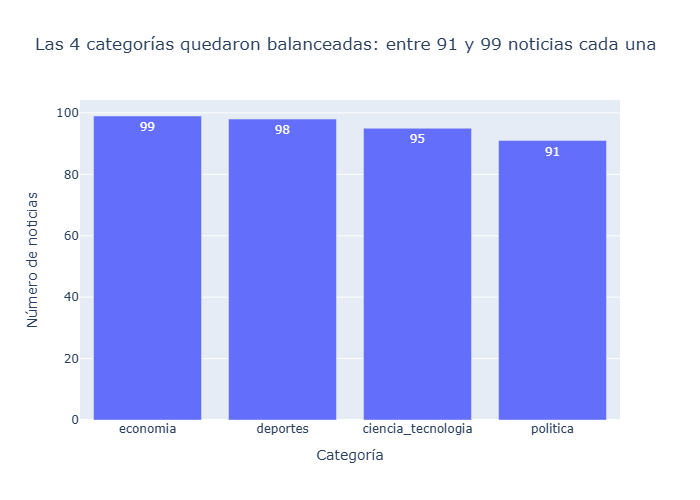

In [15]:
TITULO_GRAFICO_1 = "Las 4 categorías quedaron balanceadas: entre 91 y 99 noticias cada una"
fig = px.bar(
    conteo_categorias, x="etiqueta", y="noticias", text="noticias",
    title=TITULO_GRAFICO_1,
    labels={"etiqueta": "Categoría", "noticias": "Número de noticias"},
)
fig.show()

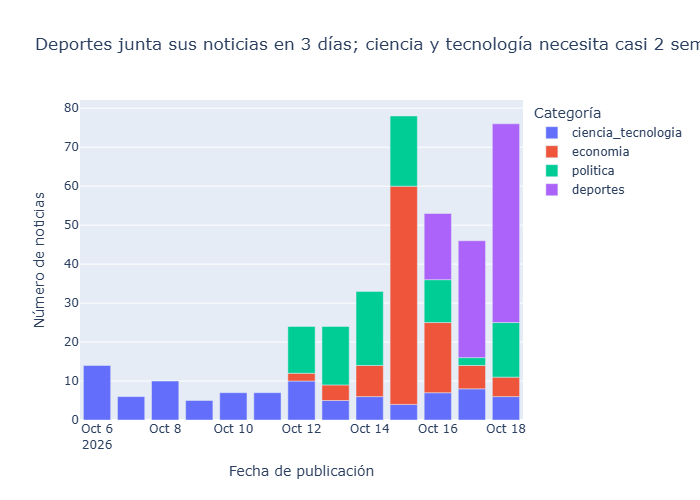

In [16]:
noticias_por_fecha = noticias_finales.groupby(["fecha", "etiqueta"]).size().reset_index(name="noticias")

TITULO_GRAFICO_2 = "Deportes junta sus noticias en 3 días; ciencia y tecnología necesita casi 2 semanas"
fig = px.bar(
    noticias_por_fecha, x="fecha", y="noticias", color="etiqueta",
    title=TITULO_GRAFICO_2,
    labels={"fecha": "Fecha de publicación", "noticias": "Número de noticias", "etiqueta": "Categoría"},
)
fig.show()

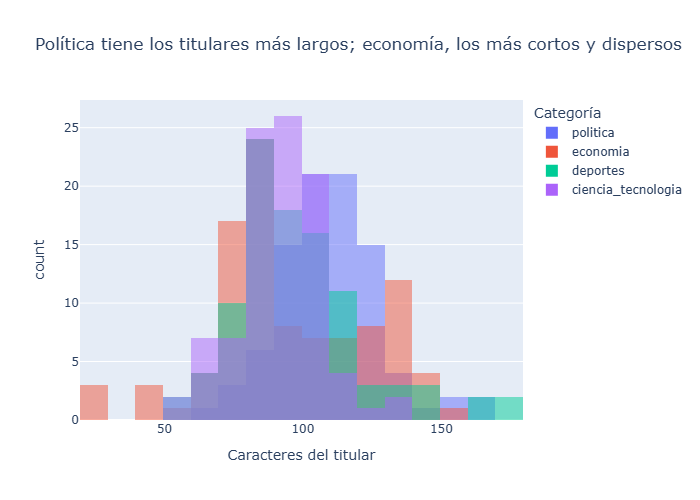

In [17]:
TITULO_GRAFICO_3 = "Política tiene los titulares más largos; economía, los más cortos y dispersos"
fig = px.histogram(
    noticias_finales, x="largo_titular", color="etiqueta", nbins=30, barmode="overlay",
    title=TITULO_GRAFICO_3,
    labels={"largo_titular": "Caracteres del titular", "etiqueta": "Categoría"},
)
fig.show()

In [18]:
noticias_finales.groupby("etiqueta")["largo_titular"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
etiqueta,,,,,,,,
ciencia_tecnologia,95.0,91.8,15.5,59.0,83.0,93.0,101.5,138.0
deportes,98.0,98.2,23.7,56.0,83.2,92.0,107.0,178.0
economia,99.0,95.7,28.5,22.0,77.5,89.0,119.5,153.0
politica,91.0,110.0,18.3,69.0,98.5,109.0,120.0,166.0


## 5. Validación: titulares más largos y más cortos

In [19]:
noticias_finales.nlargest(5, "largo_titular")[["largo_titular", "etiqueta", "titular"]]

,largo_titular,etiqueta,titular
228,178,deportes,“El jugador peruano tiene un déficit grande en nutrición y táctica que resuelve a los ...
229,171,deportes,El furioso “Que se dedique a administrar” de Guede a Franco Velazco y un Quevedo que r...
280,167,deportes,“Creo que puedo llegar a un top 3 sin que nadie se quede botado”: Raúl ‘Mono’ Orlandin...
64,166,politica,"Keiko Fujimori sobre Álvaro Vargas Llosa: “Confío en que su trayectoria, experiencia y..."
60,160,politica,Juan Sheput sobre eventual suspensión del viaje del papa León XIV al Perú: “Es posible...


In [20]:
noticias_finales.nsmallest(5, "largo_titular")[["largo_titular", "etiqueta", "titular"]]

,largo_titular,etiqueta,titular
165,22,economia,Invocación por el Perú
107,23,economia,AlaCena no tiene precio
127,24,economia,IA y Sandbox regulatorio
179,41,economia,La evolución de la confianza en los pagos
109,43,economia,Premio Nobel de Economía: la macro es micro


**¿Cuadra con el histograma?** Sí. Los 5 titulares más largos son de deportes y política, y casi
todos son **citas textuales** ("Creo que puedo llegar a un top 3..."): por eso forman la cola
derecha del histograma. Los más cortos son de economía y vienen de columnas de opinión
(`economia-opinion`, `economia-dia-1`) que se titulan con frases breves ("AlaCena no tiene
precio"). Eso explica por qué economía tiene la mayor dispersión (desviación estándar de 28.5
caracteres) y la cola izquierda del gráfico. La mayoría de titulares (78 %) mide entre 70 y 120
caracteres.

## 6. Exportación

In [21]:
columnas = ["titular", "bajada", "medio", "seccion_original", "url", "fecha", "etiqueta"]
noticias_csv = noticias_finales[columnas]
noticias_csv.to_csv("datos/noticias.csv", index=False, encoding="utf-8")

print(noticias_csv.shape)
noticias_csv.head()

(383, 7)


,titular,bajada,medio,seccion_original,url,fecha,etiqueta
0,Proyecto de Ley MAPE del gobierno propone que plantas de beneficio sean fiscalizadas ...,"A dos meses y medio para que concluya el Reinfo, el gobierno de Keiko Fujimori está po...",El Comercio,politica-gobierno,https://elcomercio.pe/politica/gobierno/el-proyecto-de-ley-mape-del-gobierno-desde-la-...,2026-10-18,politica
1,César Acuña anuncia su retiro de la política: ¿qué factores impulsarían su decisión?,"“Les doy una buena noticia: chau, política”, anunció el jueves César Acuña, excandidat...",El Comercio,politica-partidos,https://elcomercio.pe/politica/partidos/cesar-acuna-anuncia-su-retiro-de-la-politica-q...,2026-10-18,politica
2,De Gregorio Santos a “El lunarejo”: más de 8 mil condenados solicitaron el indulto pre...,"Entre los solicitantes se encuentra Gregorio Santos, exgobernador de Cajamarca, conden...",El Comercio,politica,https://elcomercio.pe/politica/indultos-presidenciales-lista-gracias-presidenciales-ke...,2026-10-18,politica
3,Comisión de Constitución del Senado reanuda este lunes debate sobre el pedido de facul...,La Comisión de Constitución del Senado continuará este lunes con la sesión extraordina...,El Comercio,politica,https://elcomercio.pe/politica/facultades-delegadas-en-vivo-comision-de-constitucion-d...,2026-10-18,politica
4,"Alfonso, ¿ahora qué?, una crónica de Fernando Vivas sobre López-Chau, líder de Ahora N...","El líder de Ahora Nación y portavoz de su bancada de senadores, Alfonso López-Chau, qu...",El Comercio,politica,https://elcomercio.pe/politica/alfonso-ahora-que-una-cronica-de-fernando-vivas-sobre-l...,2026-10-18,politica


In [22]:
# chequeo final de lo que pide el enunciado
print("Filas >= 350:          ", len(noticias_csv) >= 350)
print("7 columnas:            ", list(noticias_csv.columns) == columnas)
print("Bajadas vacías:        ", noticias_csv["bajada"].isna().sum())
print("URLs únicas:           ", noticias_csv["url"].is_unique)

Filas >= 350:           True
7 columnas:             True
Bajadas vacías:         0
URLs únicas:            True


## Qué hicimos

| Paso | Código clave |
| :--- | :--- |
| Revisar permisos | `robotparser.can_fetch(USER_AGENT, url)` |
| Descargar con pausa y 1 reintento | `descargar(url)` con `time.sleep(1.5)` |
| Leer sitemaps | `BeautifulSoup(xml, "xml").find_all("url")` |
| Bajada de cada noticia | `pagina.find("meta", attrs={"property": "og:description"})` |
| Respaldo crudo | `datos/raw/*.xml`, `bajadas_crudas.csv`, `noticias_crudas.csv` |
| Limpiar | `drop_duplicates(subset="url")` y filtro de titulares vacíos |
| Mapear a 4 categorías | `.map(categoria_por_seccion)` |
| Explorar | `px.bar`, `px.histogram` |
| Exportar | `to_csv("datos/noticias.csv")` |